# 05 · Signal standardization

Convert recordings to a consistent technical representation while preserving duration and natural level.

Run notebooks **01 → 09** in order. This notebook contains its implementation directly; it does not import project code from `src/`.

In [1]:
from pathlib import Path
import json
import hashlib
import wave
from math import gcd
import numpy as np
from scipy.signal import resample_poly
import matplotlib.pyplot as plt
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs/preprocessing.json").exists())
cfg = json.loads((root / "configs/preprocessing.json").read_text())
out = root / "data/processed" / cfg["run_name"]
reports = root / "reports/preprocessing" / cfg["run_name"]
out.mkdir(parents=True, exist_ok=True)
reports.mkdir(parents=True, exist_ok=True)

In [2]:
def load_manifest(name):
    path = out / name
    if not path.exists():
        raise FileNotFoundError(f"Run the preceding notebook first: {path}")
    return [json.loads(line) for line in path.read_text().splitlines()]

def save_manifest(name, rows):
    path = out / name
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w") as stream:
        for row in rows:
            stream.write(json.dumps(row, allow_nan=False) + "\n")

def save_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")

### Math for the next code block — PCM decoding and encoding

Decoding uses $x=q/32768$. Writing performs the approximate inverse

$$q=\operatorname{clip}\!\left(\operatorname{round}(32768x),-32768,32767\right).$$

The clip is necessary because positive PCM16 stops at $32767$, while the negative endpoint is $-32768$.

In [3]:
def read_audio(path):
    with wave.open(str(path), "rb") as wav:
        meta = {
            "sample_rate": wav.getframerate(), 
            "channels": wav.getnchannels(),
            "sample_width": wav.getsampwidth(), 
            "frames": wav.getnframes()
        }
        if wav.getcomptype() != "NONE" or meta["sample_width"] != 2:
            raise ValueError("Only uncompressed PCM16 WAV is supported")
        pcm = wav.readframes(meta["frames"])
    if not meta["frames"] or len(pcm) != meta["frames"] * meta["channels"] * 2:
        raise ValueError("Empty or truncated PCM")
    audio = np.frombuffer(pcm, dtype="<i2").reshape(-1, meta["channels"]).astype(np.float32) / 32768
    meta["pcm_sha256"] = hashlib.sha256(pcm).hexdigest()
    return audio, meta

def write_audio(path, audio, rate):
    path.parent.mkdir(parents=True, exist_ok=True)
    pcm = np.clip(np.rint(np.asarray(audio) * 32768), -32768, 32767).astype("<i2")
    with wave.open(str(path), "wb") as wav:
        wav.setnchannels(1); wav.setsampwidth(2); wav.setframerate(rate)
        wav.writeframes(pcm.tobytes())

## Channel and sample-rate conversion

There is no trimming, denoising, padding, or per-file gain normalization.

### Math for the next code block — mono conversion and resampling

For $C$ input channels, mono conversion is the channel mean

$$m[n]=\frac1C\sum_{c=1}^{C}x[n,c].$$

For source rate $f_{in}$ and target rate $f_{out}$, reduce the ratio with $g=\gcd(f_{in},f_{out})$:

$$p=\frac{f_{out}}g,\qquad q=\frac{f_{in}}g.$$

Polyphase resampling implements “upsample by $p$, low-pass filter, downsample by $q$.” Ideally,

$$y[m]=\sum_n m[n]\,h\!\left(\frac{mq}{p}-n\right).$$

The current corpus is already 16 kHz mono, so this stage is an identity transform for this run.

In [4]:
def standardize_signal(
        audio, 
        source_rate, 
        target_rate
):
    signal = np.asarray(
        audio,
        dtype=np.float32
    )
    if signal.ndim==2: 
        signal=signal.mean(axis=1)
    if source_rate!=target_rate:
        divisor=gcd(
            source_rate,
            target_rate
        )
        signal=resample_poly(
            signal,
            target_rate//divisor,
            source_rate//divisor
        ).astype(np.float32)
    return signal

In [5]:
rows=[]
for record in load_manifest("04_split_manifest.jsonl"):
    audio,meta=read_audio(root/record["raw_path"])
    signal=standardize_signal(audio,meta["sample_rate"],cfg["sample_rate"])
    path=out/"05_standardized"/record["split"]/f"{record['id']}.wav"
    write_audio(
        path,
        signal,
        cfg["sample_rate"]
    )
    rows.append(
        {
            **record,
            "audio_path":str(path.relative_to(root)),
            "standardized_rate":cfg["sample_rate"],
            "standardized_samples":len(signal)
        }
    )

In [6]:
save_manifest("05_standardized.jsonl",rows)

In [7]:
display({"recordings":len(rows),"sample_rates":sorted({r["standardized_rate"] for r in rows}),
         "channels":[1],"identity_conversion":all(r["sample_rate"]==cfg["sample_rate"] and r["channels"]==1 for r in rows)})

{'recordings': 7973,
 'sample_rates': [16000],
 'channels': [1],
 'identity_conversion': True}

## Waveform comparison

In [8]:
INK, MUTED, BLUE, TEAL, AMBER, RED = "#152b42", "#586c7d", "#3265bb", "#087f8c", "#ba6b10", "#bf4545"
plt.rcParams.update({"figure.facecolor":"#f4f7fb", "axes.facecolor":"white",
                     "axes.edgecolor":"#c8d5e2", "axes.labelcolor":INK,
                     "xtick.color":MUTED, "ytick.color":MUTED, "font.size":11})

def finish_figure(fig, name):
    directory = reports / "figures"
    directory.mkdir(parents=True, exist_ok=True)
    fig.savefig(directory / f"{name}.png", dpi=170, bbox_inches="tight")
    fig.savefig(directory / f"{name}.svg", bbox_inches="tight")
    plt.show()

### Math for the next code block — waveform time axis

Sample index $n$ is displayed at

$$t_n=\frac{n}{f_s}\ \text{seconds}.$$

Matching source and standardized curves confirm that the identity-format conversion preserved sample values and duration.

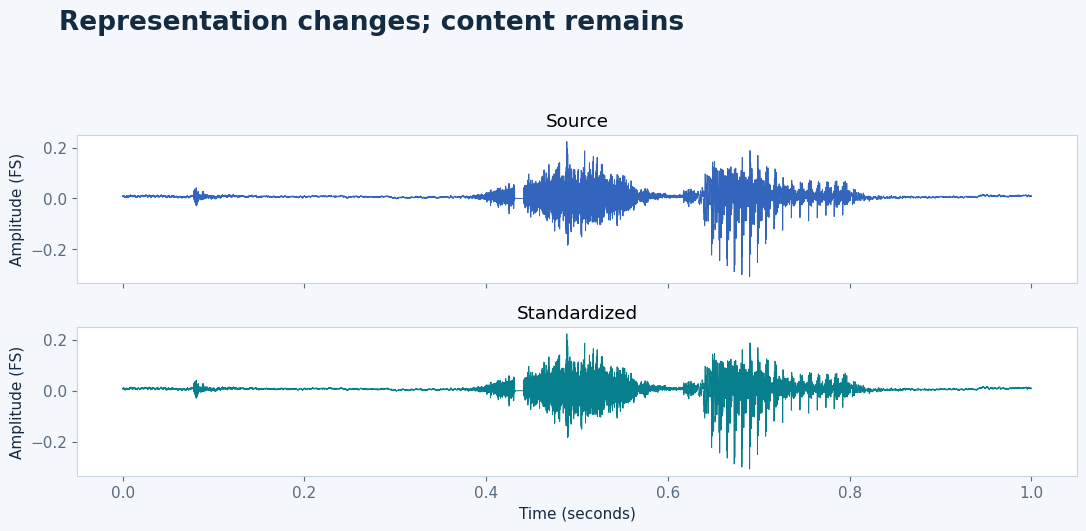

In [9]:
example=next(r for r in rows if r["is_keyword"] and r["split"]=="train")
before,_=read_audio(root/example["raw_path"])
after,_=read_audio(root/example["audio_path"])
fig,axes=plt.subplots(2,1,figsize=(11,5.5),sharex=True,sharey=True)
for ax,signal,title,color in zip(axes,[before[:,0],after[:,0]],["Source","Standardized"],[BLUE,TEAL]):
    ax.plot(np.arange(len(signal))/cfg["sample_rate"],signal,lw=.7,color=color)
    ax.set(title=title,ylabel="Amplitude (FS)")
axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("Representation changes; content remains",x=.06,ha="left",fontsize=19,weight="bold",color=INK)
fig.tight_layout(rect=(0,.02,1,.9))
finish_figure(fig,"05_standardization")

Continue with [06 · Data augmentation](06_data_augmentation.ipynb).